NULL values and missing values for:
- consumer_fraud_probability and merchant_fraud_probability are imputed using ML
- consumer_district_income is imputed with median income of all districts 

Outliers are not omitted

In [8]:
transactions_df = spark.read.parquet(str(root / "tables/curated/transactions"))
null_counts_df = transactions_df.select([
    F.sum(F.col(column).isNull().cast("long")).alias(column)
    for column in transactions_df.columns
])
null_counts_df.show(truncate=False)

+--------+--------------+------------+-------+------------+--------------------------+--------------------------+-----------------+---------------+------------------------+--------------+-----------------------+-----------------------+---------------------+-------------+-----------+
|order_id|order_datetime|dollar_value|user_id|merchant_abn|consumer_fraud_probability|merchant_fraud_probability|consumer_postcode|consumer_gender|consumer_district_income|income_matched|consumer_record_matched|merchant_record_matched|consumer_avg_spending|spending_diff|order_month|
+--------+--------------+------------+-------+------------+--------------------------+--------------------------+-----------------+---------------+------------------------+--------------+-----------------------+-----------------------+---------------------+-------------+-----------+
|0       |0             |0           |0      |0           |14115157                  |14191446                  |0                |0              |0

In [1]:
from pathlib import Path
from zipfile import ZipFile
import requests

root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tables/landing").is_dir())
boundary_dir = root / "tables/landing/abs_2021/postal_areas_2021"
boundary_dir.mkdir(parents=True, exist_ok=True)
boundary_zip = boundary_dir / "POA_2021_AUST_GDA2020_SHP.zip"
boundary_url = ("https://www.abs.gov.au/statistics/standards/australian-statistical-geography-standard-asgs/"
                "edition-3-july-2021-june-2026/access-and-downloads/digital-boundary-files/"
                "POA_2021_AUST_GDA2020_SHP.zip")

if not next(boundary_dir.rglob("*.shp"), None):
    with requests.get(boundary_url, stream=True, timeout=180) as response:
        response.raise_for_status()
        with boundary_zip.open("wb") as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)
    with ZipFile(boundary_zip) as archive:
        archive.extractall(boundary_dir)

postal_areas_shapefile = next(boundary_dir.rglob("*.shp"))
print(f"Postal Areas shapefile ready: {postal_areas_shapefile}")

Postal Areas shapefile ready: /Users/karkar/Desktop/Folder/2026/Applied Data Science/Project 2/industry-project-group-19/tables/landing/abs_2021/postal_areas_2021/POA_2021_AUST_GDA2020.shp


/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


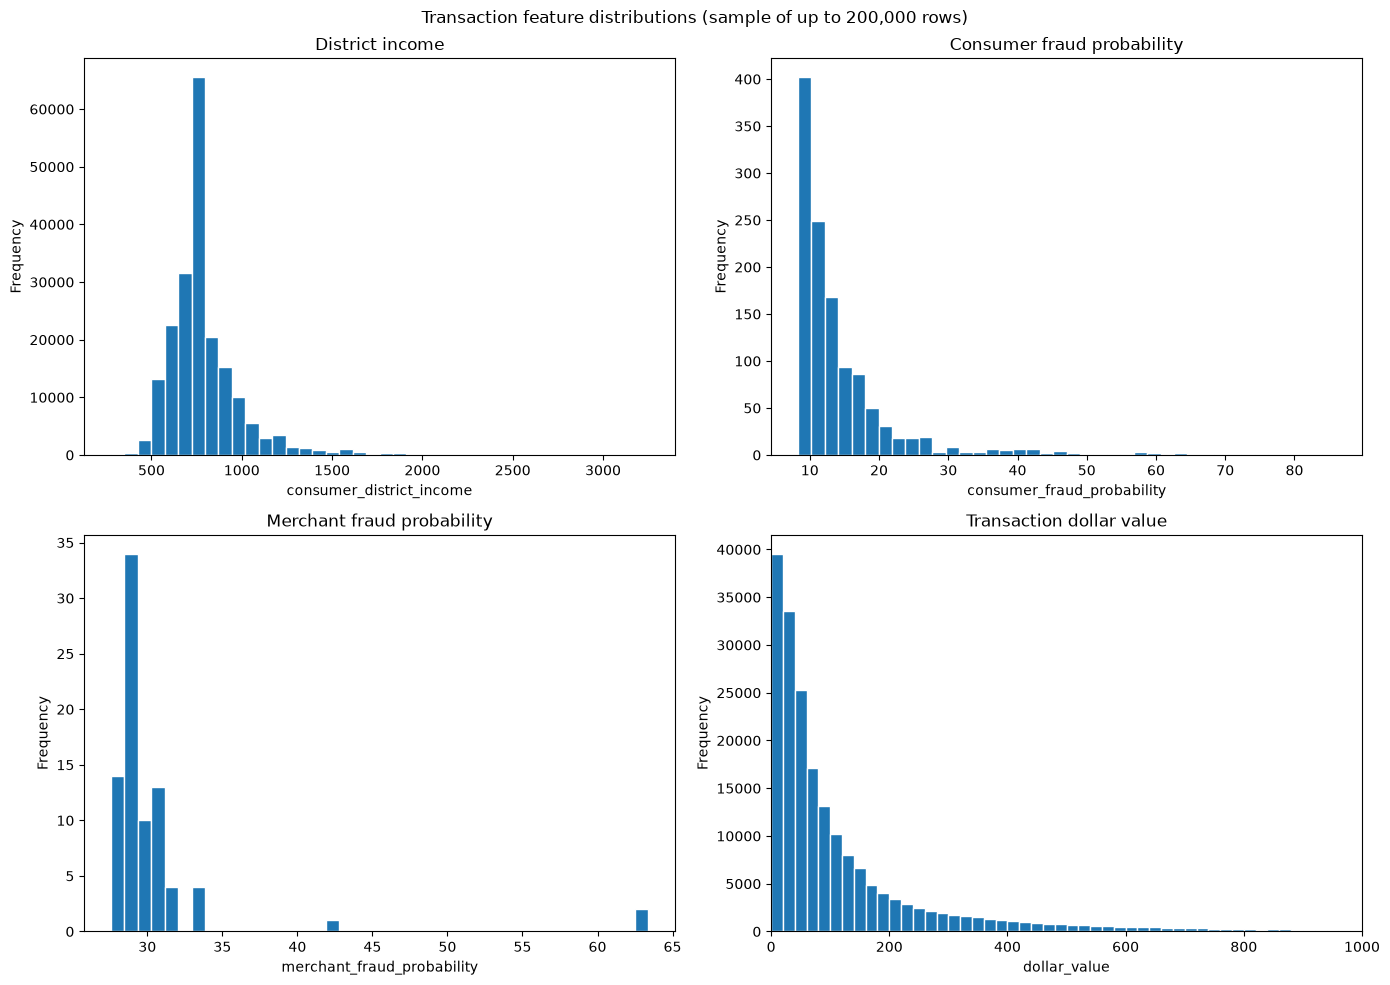

/opt/homebrew/lib/python3.11/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


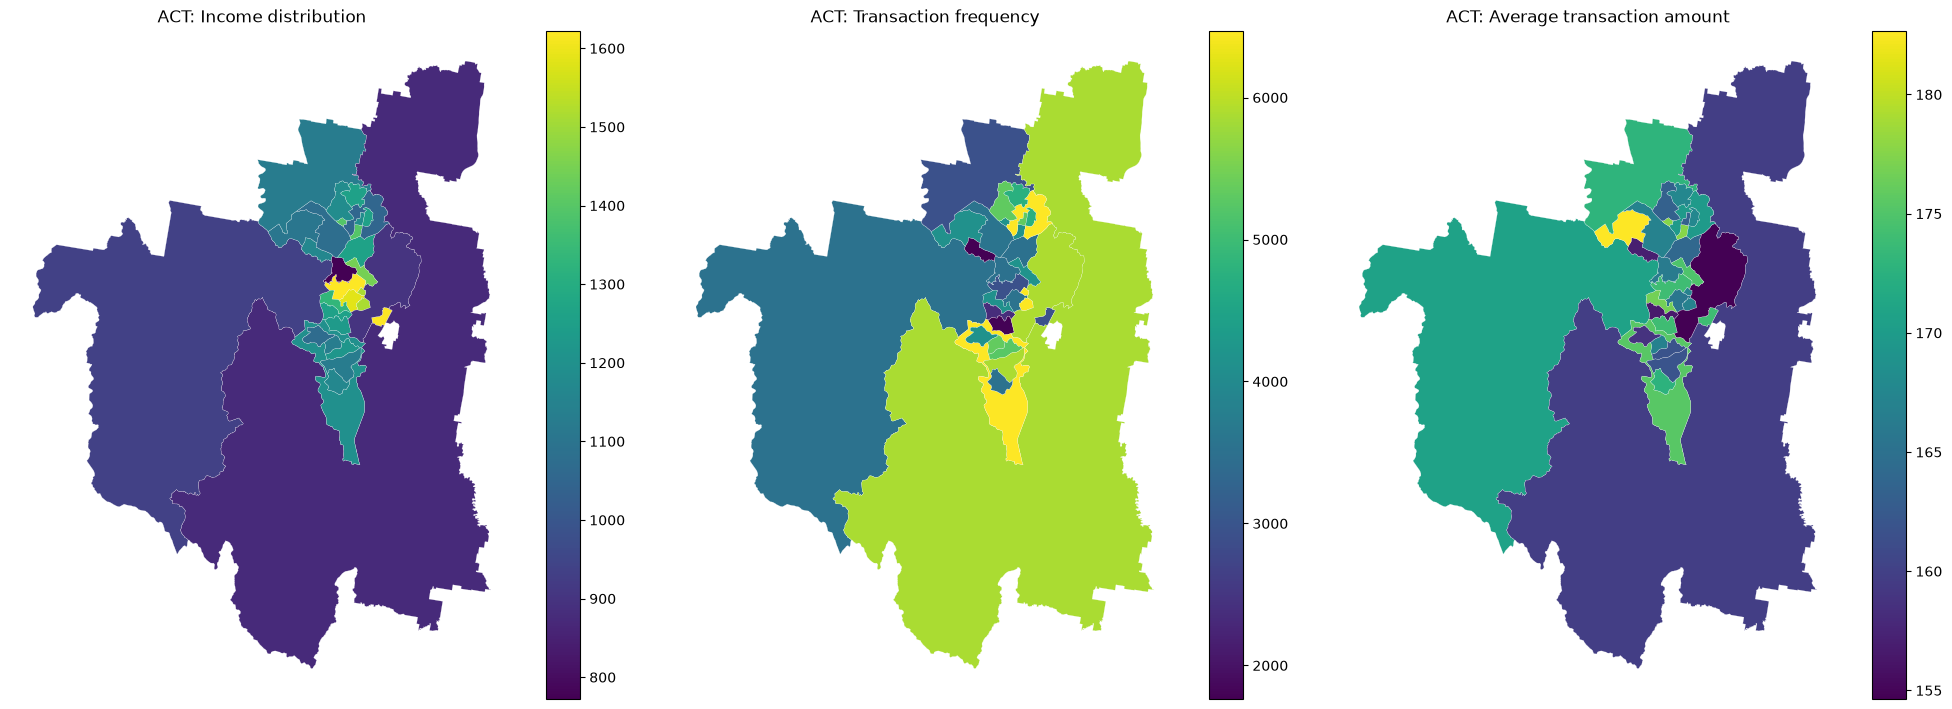

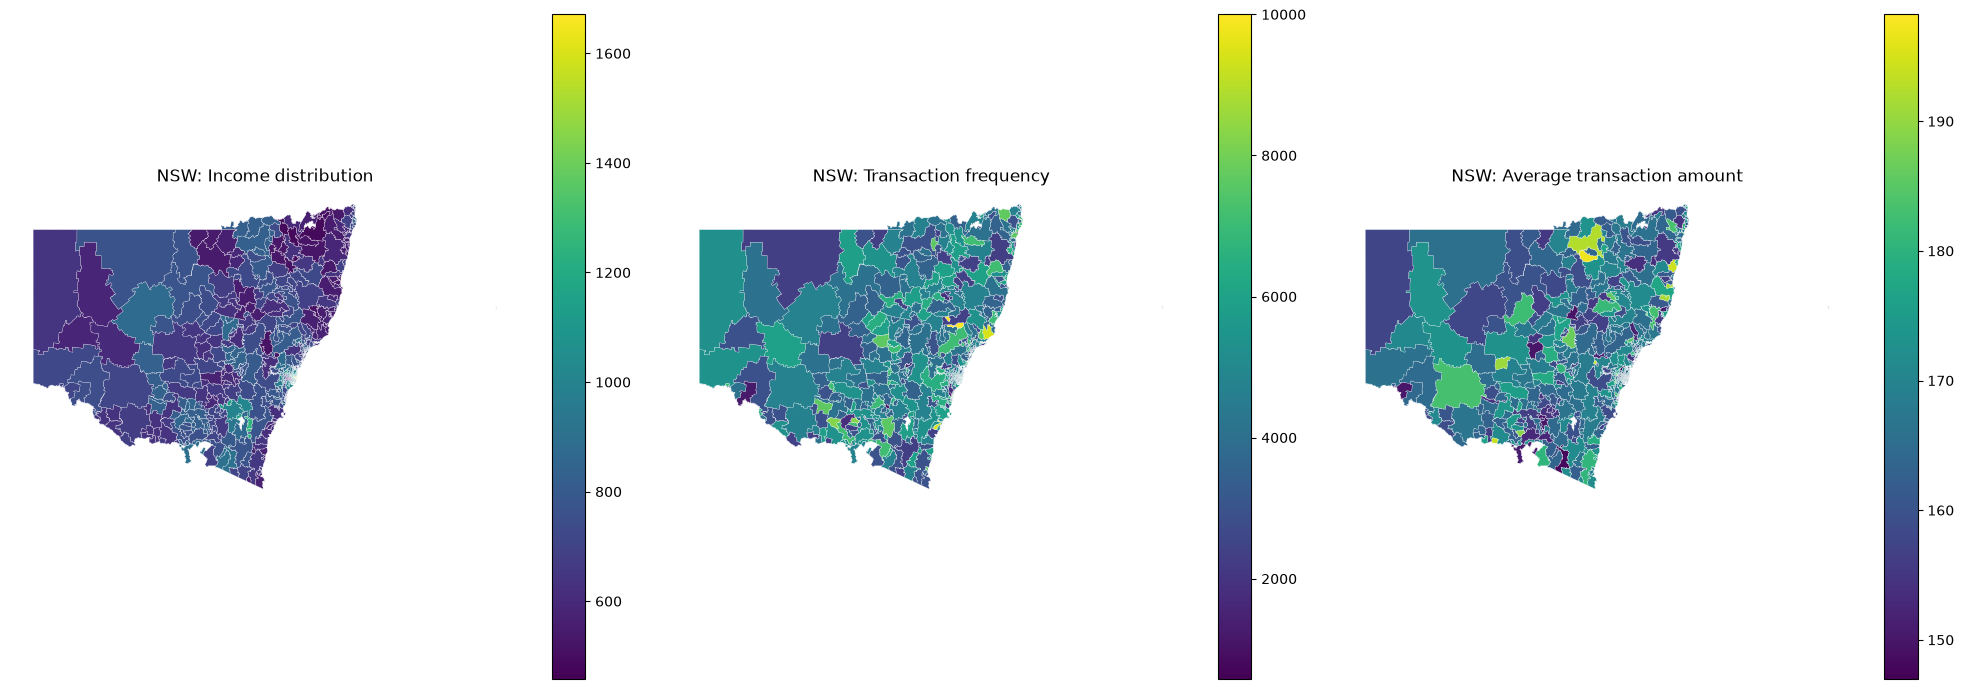

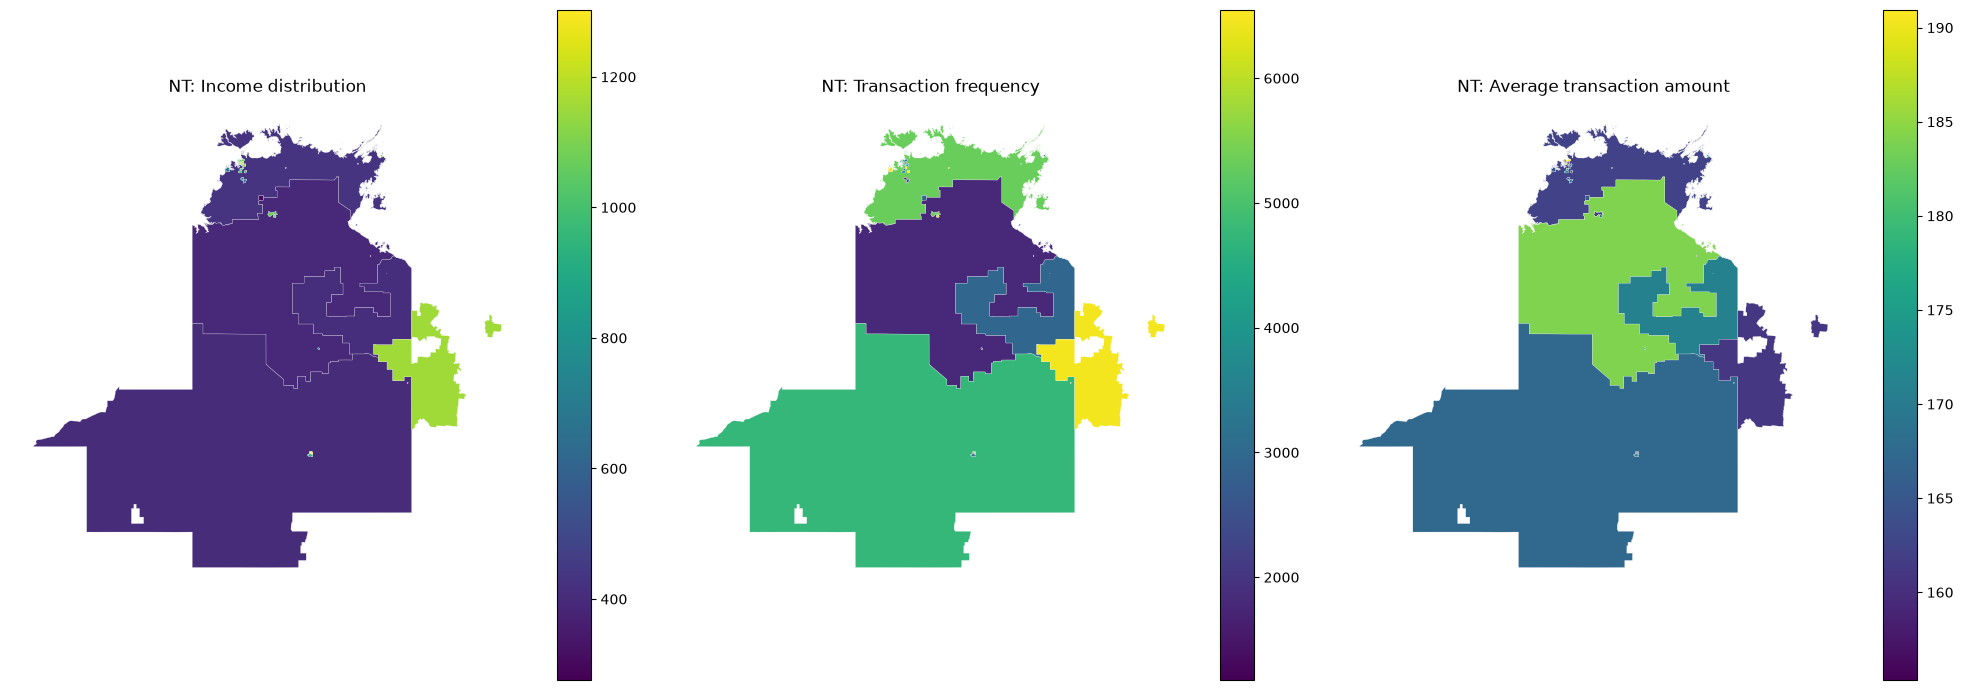

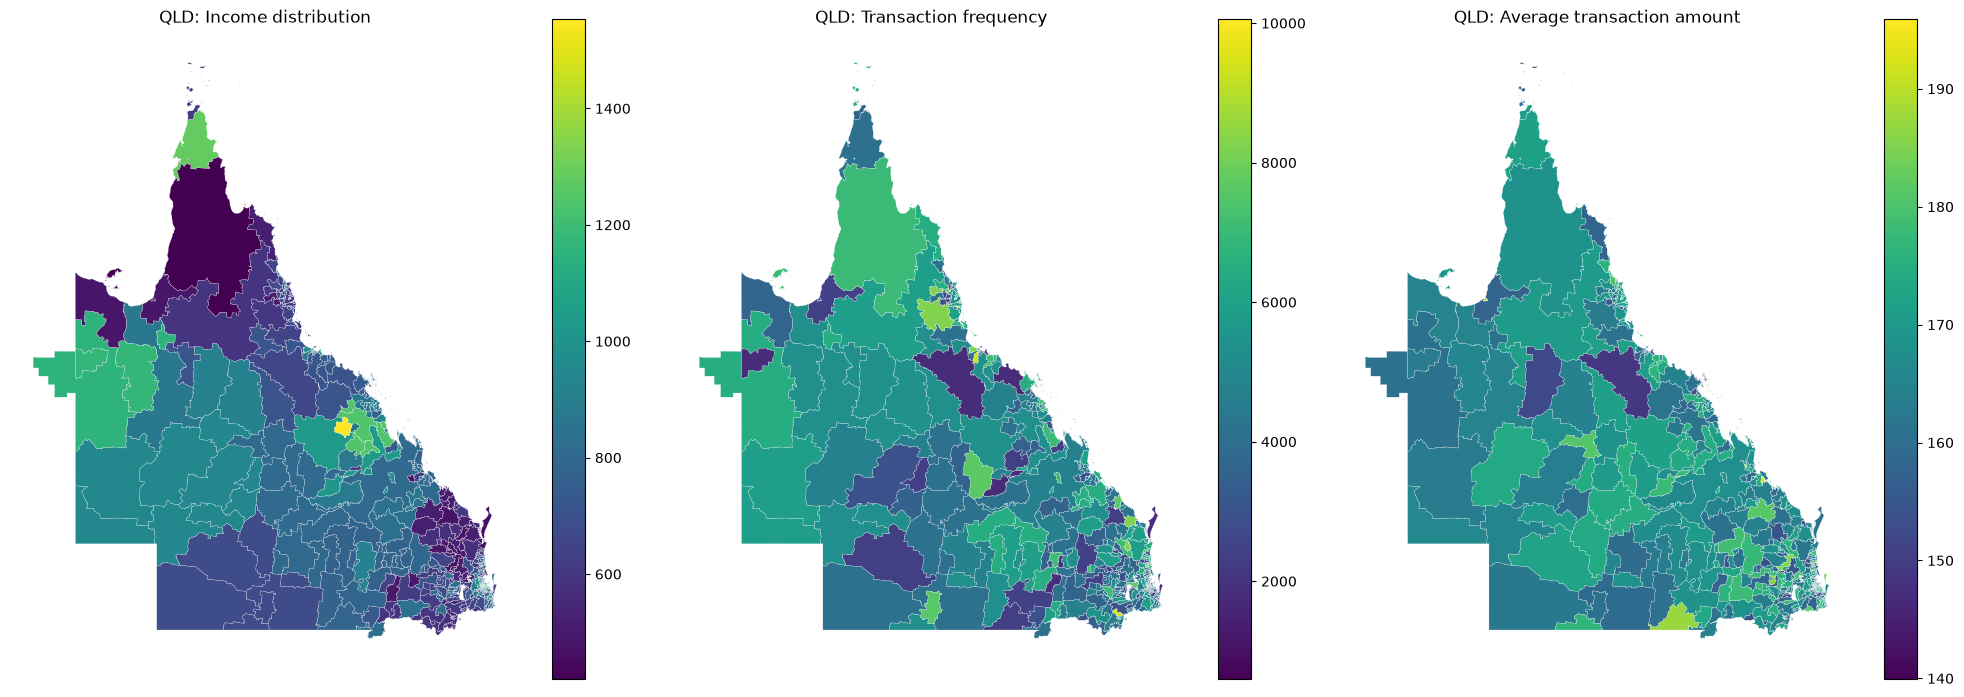

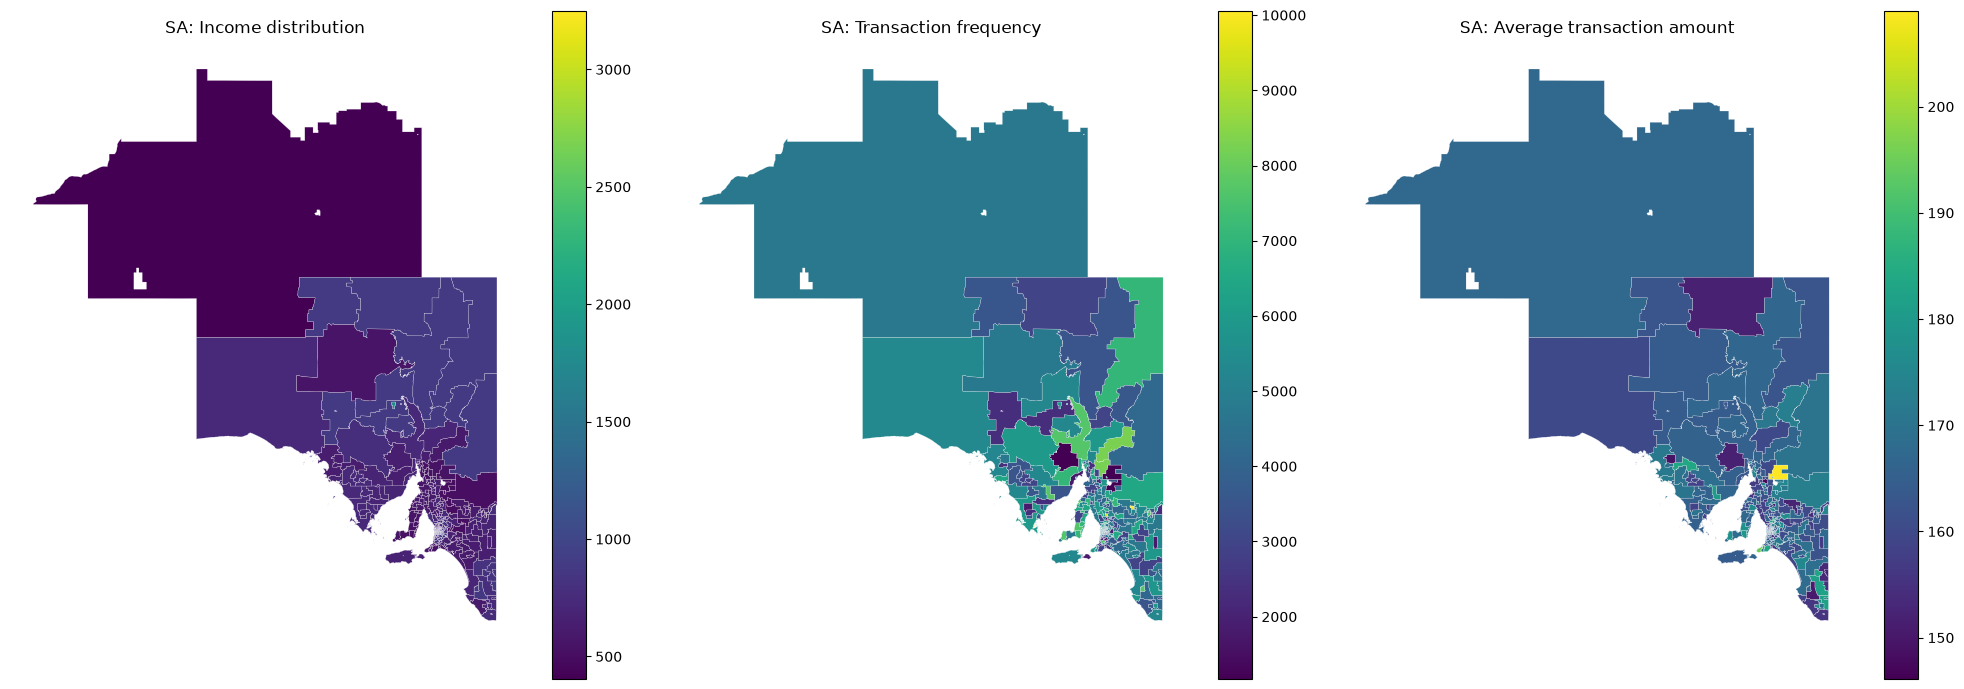

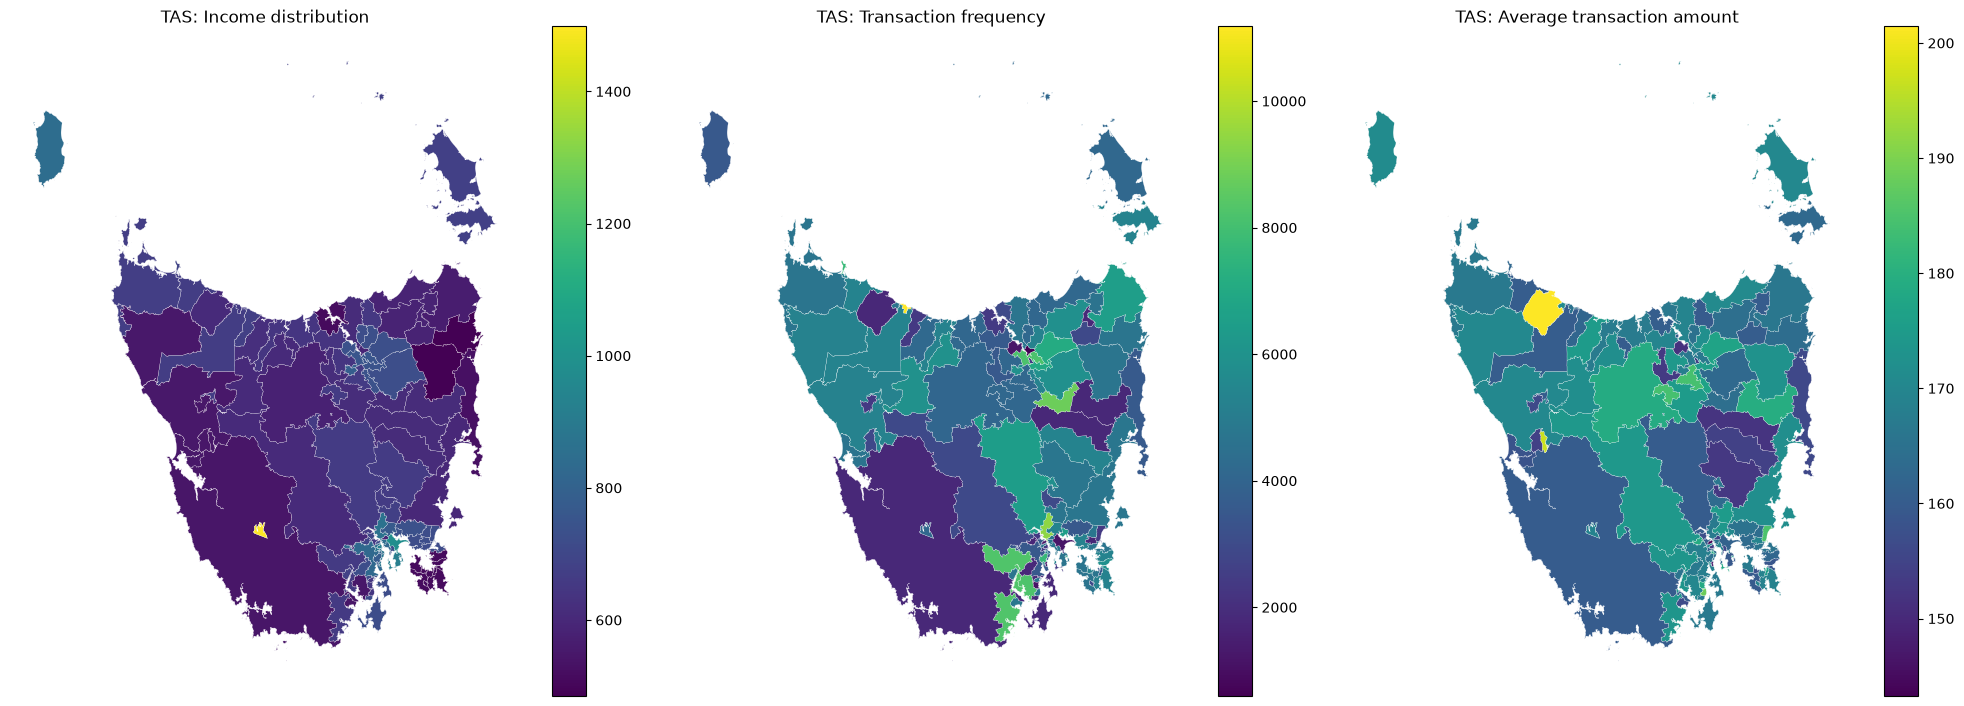

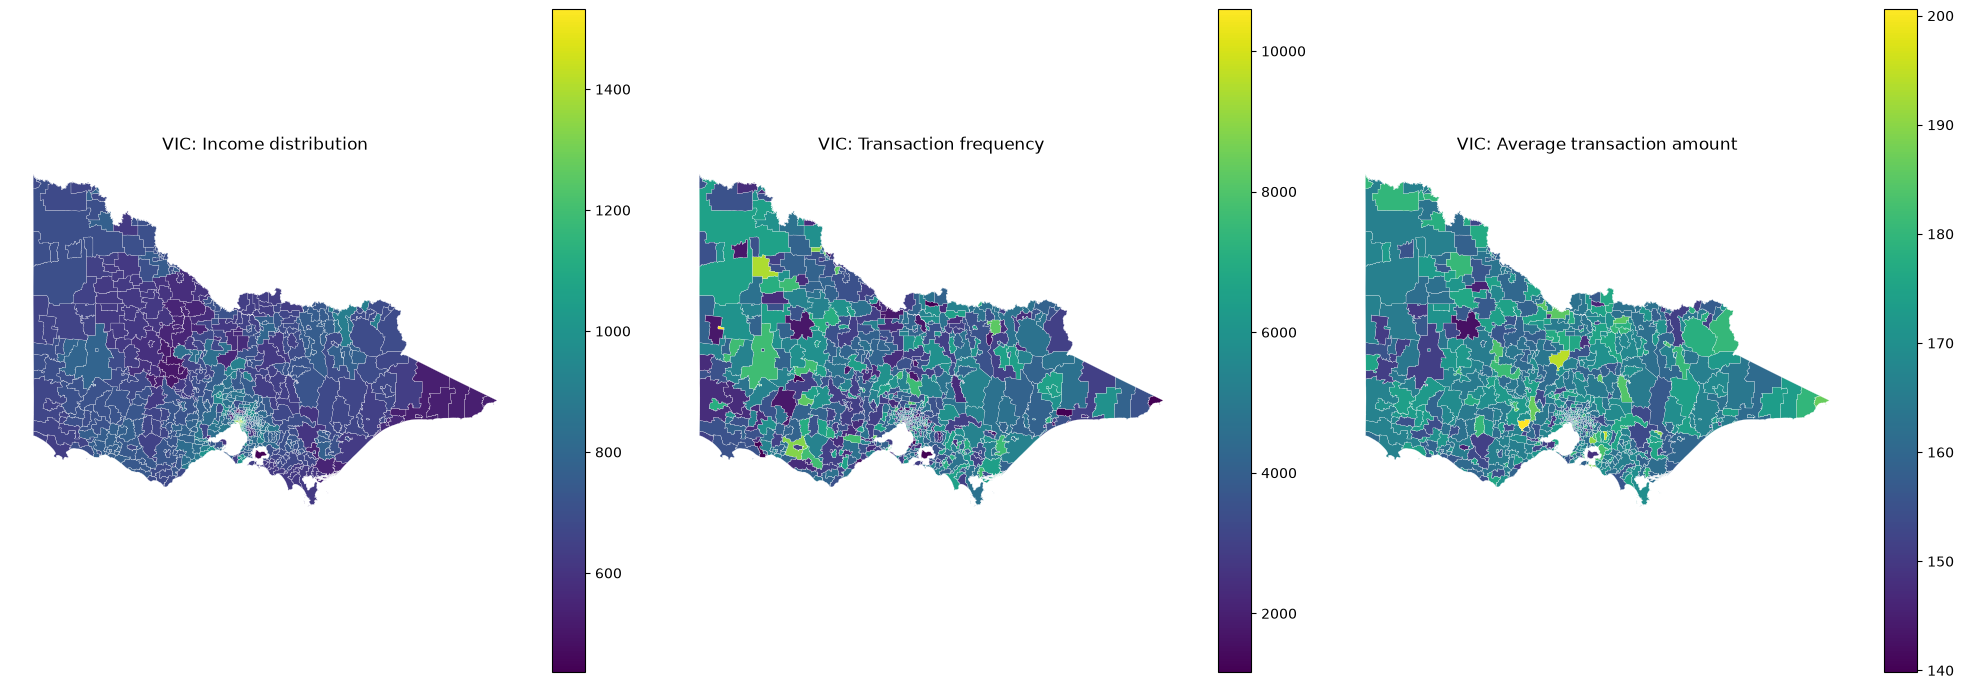

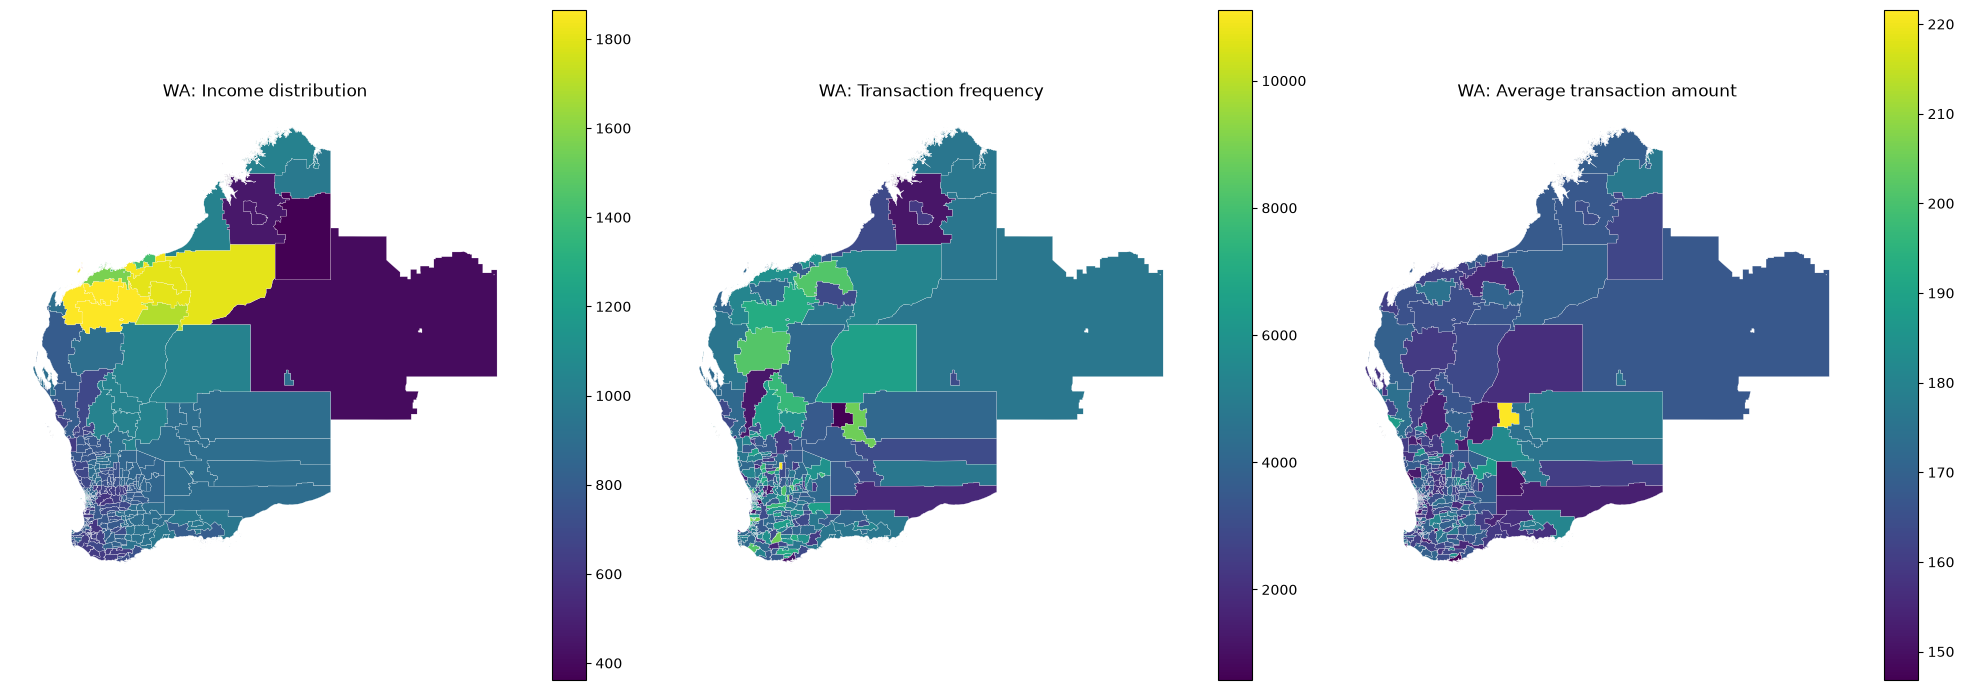

In [3]:
from pathlib import Path
import geopandas as gpd
import matplotlib.pyplot as plt
from pyspark.sql import SparkSession, functions as F

spark = SparkSession.builder.getOrCreate()
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "tables/curated/transactions").is_dir())
transactions_for_plots = spark.read.parquet(str(root / "tables/curated/transactions"))

histogram_columns = {
    "consumer_district_income": "District income",
    "consumer_fraud_probability": "Consumer fraud probability",
    "merchant_fraud_probability": "Merchant fraud probability",
    "dollar_value": "Transaction dollar value",
}
histogram_sample = (transactions_for_plots.select(*histogram_columns)
                    .sample(withReplacement=False, fraction=0.02, seed=19)
                    .limit(200000).toPandas())
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
for axis, (column, title) in zip(axes.flat, histogram_columns.items()):
    if column == "dollar_value":
        axis.hist(histogram_sample[column].dropna(), bins=50, range=(0, 1000), edgecolor="white")
        axis.set_xlim(0, 1000)
    else:
        axis.hist(histogram_sample[column].dropna(), bins=40, edgecolor="white")
    axis.set(title=title, xlabel=column, ylabel="Frequency")
fig.suptitle("Transaction feature distributions (sample of up to 200,000 rows)")
fig.tight_layout()
plt.show()

postcode_metrics = (transactions_for_plots
    .where(F.col("consumer_postcode").isNotNull())
    .groupBy("consumer_postcode")
    .agg(F.avg("consumer_district_income").alias("income_distribution"),
         F.count(F.lit(1)).alias("transaction_frequency"),
         F.avg("dollar_value").alias("average_transaction_amount")))
postcode_states = (spark.read.parquet(str(root / "tables/curated/postcode_income"))
    .select(F.col("postcode").alias("consumer_postcode"), "state").distinct())
postcode_metrics = postcode_metrics.join(postcode_states, "consumer_postcode", "left").toPandas()
postcode_metrics["consumer_postcode"] = postcode_metrics["consumer_postcode"].astype(str).str.zfill(4)

boundary_dir = root / "tables/landing/abs_2021/postal_areas_2021"
postal_areas_shapefile = next(boundary_dir.rglob("*.shp"))
postal_areas = gpd.read_file(postal_areas_shapefile)[["POA_CODE21", "geometry"]]
postal_areas["POA_CODE21"] = postal_areas["POA_CODE21"].astype(str).str.zfill(4)
mapped_postcodes = postal_areas.merge(postcode_metrics, left_on="POA_CODE21",
                                          right_on="consumer_postcode", how="inner")
map_columns = {
    "income_distribution": "Income distribution",
    "transaction_frequency": "Transaction frequency",
    "average_transaction_amount": "Average transaction amount",
}
for state in sorted(state for state in mapped_postcodes["state"].dropna().unique() if state != "OT"):
    state_map = mapped_postcodes[mapped_postcodes["state"] == state]
    fig, axes = plt.subplots(1, 3, figsize=(20, 7))
    for axis, (column, title) in zip(axes, map_columns.items()):
        state_map.plot(column=column, ax=axis, cmap="viridis", legend=True,
                       edgecolor="white", linewidth=0.15)
        axis.set_title(f"{state}: {title}")
        axis.set_axis_off()
    fig.tight_layout()
    plt.show()

Transaction for each postcode

In [7]:
import math

summary_data = transactions_for_plots.select(
    F.col("consumer_district_income").alias("district_income"),
    F.col("dollar_value").alias("transaction_dollar_value")
)
summary_stats = summary_data.summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")

distribution_stats = summary_data.agg(
    F.count("district_income").alias("district_n"),
    F.avg("district_income").alias("district_mean"),
    F.stddev("district_income").alias("district_stddev"),
    F.count("transaction_dollar_value").alias("transaction_n"),
    F.avg("transaction_dollar_value").alias("transaction_mean"),
    F.stddev("transaction_dollar_value").alias("transaction_stddev")
).first()

district_threshold = math.sqrt(2 * math.log(distribution_stats["district_n"]))
transaction_threshold = math.sqrt(2 * math.log(distribution_stats["transaction_n"]))
outlier_counts = summary_data.agg(
    F.sum(F.when(
        F.abs((F.col("district_income") - distribution_stats["district_mean"]) / distribution_stats["district_stddev"]) > district_threshold, 1
    ).otherwise(0)).alias("district_income"),
    F.sum(F.when(
        F.abs((F.col("transaction_dollar_value") - distribution_stats["transaction_mean"]) / distribution_stats["transaction_stddev"]) > transaction_threshold, 1
    ).otherwise(0)).alias("transaction_dollar_value")
).first()

outlier_row = summary_stats.limit(1).select(
    F.lit("outlier_count").alias("summary"),
    F.lit(str(outlier_counts["district_income"])).alias("district_income"),
    F.lit(str(outlier_counts["transaction_dollar_value"])).alias("transaction_dollar_value")
)
print(f"Z-score thresholds — district income: {district_threshold:.4f}; transaction dollar value: {transaction_threshold:.4f}")
summary_stats.unionByName(outlier_row).show(truncate=False)

Z-score thresholds — district income: 5.7391; transaction dollar value: 5.7391


+-------------+-----------------+------------------------+
|summary      |district_income  |transaction_dollar_value|
+-------------+-----------------+------------------------+
|count        |14195505         |14195505                |
|mean         |785.1704245133125|166.228953908917        |
|stddev       |195.737514976078 |517.8505602612782       |
|min          |276.0            |9.756658099412162E-8    |
|25%          |674.0            |26.127810378412235      |
|50%          |754.0179737922941|62.223490757969735      |
|75%          |843.0            |150.4311770804771       |
|max          |3250.0           |105193.88578925544      |
|outlier_count|3548             |46192                   |
+-------------+-----------------+------------------------+

